# Notebook 1 — Understanding the data, and scoring signal quality per sensor

**Goal of this notebook:** look at real brain recordings until they make sense, then build the first version of a
*signal-quality score* — a number from 0 (useless) to 1 (clean) for every sensor, every 2 seconds.

**How to use it:** run the cells top to bottom (Shift+Enter). Read the text above each plot first — it tells you what to look for.

> **Note:** `quality.py` has since been upgraded to version 2 (8 checks, split into *contact* and *artifact*, with a
> motion check that uses the head motion sensor). This notebook shows the checks that need only the brain sensors.
> The full upgrade and its test against the brain's response are in `reports/signal_quality_report.md`.

### Words used in this notebook (all of them)
| Word | Meaning |
|---|---|
| **EEG** | Electro-encephalo-graphy = recording the brain's electrical activity with sensors on the scalp |
| **sensor / electrode** | One small metal disc touching the scalp. Same idea as one PPG sensor |
| **channel** | The signal from one sensor over time — one row of numbers |
| **µV (microvolt)** | One millionth of a volt. Brain signals are ~10–100 µV. A AA battery is 1,500,000 µV |
| **Hz** | "per second". *Sampling rate* 500 Hz = 500 readings per second. A *rhythm* at 10 Hz = 10 ups-and-downs per second |
| **artifact** | Anything in the recording that is **not** brain: blinks, muscles, movement, electrical hum |
| **IMU** | Motion sensor (accelerometer + gyroscope + compass) — like the one in your wrist wearable |
| **spectrum** | How much of each rhythm (Hz) a signal contains — like finding heart rate as the peak in a PPG spectrum |
| **window** | A short chunk of the recording (here 2 s) that we score separately |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy.signal import welch

from eegqc import lee, quality, validate

mne.set_log_level("error")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SUB = "sub-02"          # this person has some clearly badly-attached sensors -> good for learning
STANDING, JOGGING = "ses-02", "ses-05"
TASK = "ERP"

## 1. How was this recorded?

One volunteer at a time, in a lab in Korea (Lee et al., 2021, *Scientific Data*):

- They wore a **cap with 32 sensors** on the scalp, with a little conductive **gel** under each one so it touches the skin well.
- **3 motion sensors (IMU)**: forehead, left ankle, right ankle.
- The dataset also has **14 sensors behind the ears** and **4 sensors around the eyes**.

> **Our scope = what Sabi's cap has: scalp sensors + a motion sensor on the head.** Sabi's cap has no ear or eye
> sensors, so we **ignore the ear sensors** and the ankle motion sensors completely. The **eye sensors are used only as an
> answer key**: they tell us when real blinks happened, so we can check whether we detect blinks from the scalp alone.
- They **stood, walked slowly, walked fast, and jogged** on a treadmill — one recording per speed.
- During each recording they watched a screen: letters flashed every ~1 s and they looked out for one rare pattern
  ("OOO" among "XXX"). Spotting the rare one makes the brain produce a small, famous bump ~0.3 s later.
  We'll use that bump later to check whether the brain signal survives the movement.

Below we load the **standing** recording of one person and describe what is inside, in plain words.

In [2]:
raw = lee.load_eeg(SUB, STANDING, TASK)
events = lee.erp_events(raw)

scalp, ear = lee.scalp_channels(raw), lee.ear_channels(raw)
print(f"Recording: {SUB}, {lee.SPEEDS[STANDING]}, task = watching flashing letters")
print(f"  length            : {raw.times[-1]/60:.1f} minutes")
print(f"  readings / second : {raw.info['sfreq']:.0f} (so {raw.n_times:,} readings per sensor)")
print(f"  scalp sensors     : {len(scalp)}  -> {', '.join(scalp)}")
print(f"  eye sensors       : {len(lee.EOG_CHANNELS)}  (used ONLY as the answer key for blinks)")
print(f"  ear sensors       : {len(ear)}  (ignored - Sabi's cap has none)")
print(f"  flashes on screen : {len(events)}  (rare 'target' = {np.sum(events[:,2]==2)}, common = {np.sum(events[:,2]==1)})")
print(f"  sensors the authors marked 'bad': {lee.authors_bad_channels(SUB, STANDING, TASK)}")

Recording: sub-02, standing (0 m/s), task = watching flashing letters
  length            : 11.5 minutes
  readings / second : 500 (so 344,222 readings per sensor)
  scalp sensors     : 32  -> Fp1, Fp2, AFz, F7, F3, Fz, F4, F8, FC5, FC1, FC2, FC6, C3, Cz, C4, CP5, CP1, CP2, CP6, P7, P3, Pz, P4, P8, PO7, PO3, POz, PO4, PO8, O1, Oz, O2
  eye sensors       : 4  (used ONLY as the answer key for blinks)
  ear sensors       : 14  (ignored - Sabi's cap has none)
  flashes on screen : 300  (rare 'target' = 60, common = 240)
  sensors the authors marked 'bad': ['Fp2', 'F7', 'Fz', 'FC1', 'FC2', 'Cz']


## 2. Where are the sensors? (the "10-20" naming system)

Every EEG lab names scalp positions the same way, so a name tells you exactly where a sensor sits:

- **Letter = brain region:** `Fp` front of forehead, `F` frontal, `C` central (top), `P` parietal (upper back),
  `O` occipital (back of head, vision), `T` temporal (sides).
- **Number = side:** odd = left, even = right, bigger number = further from the middle.
- **`z` = on the midline** (zero). `Pz` = top-back middle — the best spot for the "spotted it!" bump.

The picture is the head seen **from above, nose at the top**.

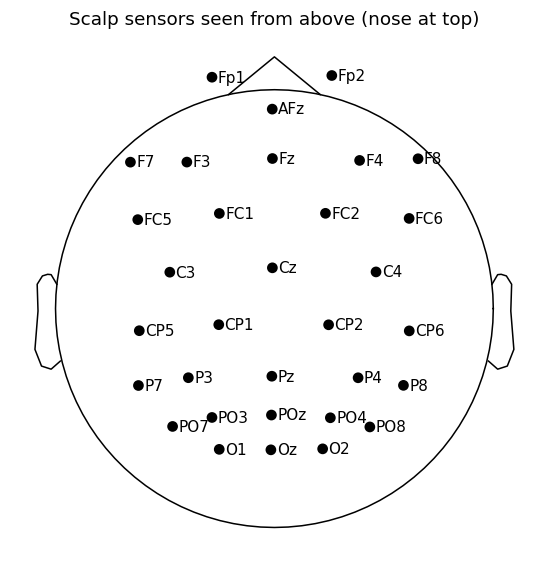

In [3]:
fig = mne.viz.plot_sensors(raw.copy().pick(scalp).info, show_names=True, show=False)
fig.set_size_inches(5, 5)
plt.title("Scalp sensors seen from above (nose at top)")
plt.show()

## 3. What does the raw brain signal look like?

Each line below is one sensor over 10 seconds. We remove very slow drift and fast hum (keep 0.5–40 Hz) so the
picture is readable — exactly like you'd band-pass a PPG before looking at it.

**What to look for**
- Normal brain signal = irregular wiggles of roughly **±20–50 µV**. It never looks clean like a heartbeat.
- **Big slow bumps on the front sensors (`Fp1`, `Fp2`) that fade towards the back** — those are **eye blinks**.
  The eyeball is electrically charged, so moving the eyelid creates a large voltage near the forehead.
- Neighbouring sensors look similar — the skull smears brain activity over several centimetres.

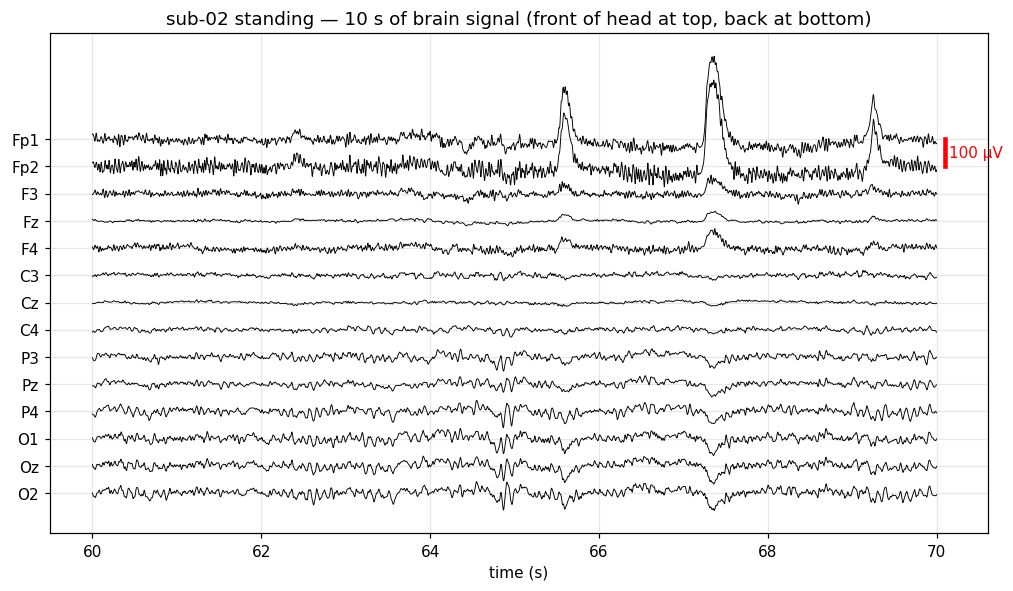

In [4]:
def stacked_plot(data_uv, names, sfreq, t0, dur, title, spacing=100, ax=None, color="k"):
    i0, i1 = int(t0*sfreq), int((t0+dur)*sfreq)
    t = np.arange(i0, i1) / sfreq
    ax = ax or plt.subplots(figsize=(11, 0.35*len(names)+1))[1]
    for k, (row, name) in enumerate(zip(data_uv[:, i0:i1], names)):
        ax.plot(t, row - row.mean() - k*spacing, lw=0.6, color=color)
    ax.set_yticks([-k*spacing for k in range(len(names))], names)
    ax.set_xlabel("time (s)"); ax.set_title(title)
    ax.plot([t[-1]+0.1]*2, [0, -spacing], color="r", lw=3); ax.text(t[-1]+0.15, -spacing/2, f"{spacing} µV", color="r", va="center")
    return ax

filtered = raw.copy().filter(0.5, 40, picks=["eeg", "eog"])
show = ["Fp1", "Fp2", "F3", "Fz", "F4", "C3", "Cz", "C4", "P3", "Pz", "P4", "O1", "Oz", "O2"]
stacked_plot(filtered.get_data(picks=show)*1e6, show, raw.info["sfreq"], t0=60, dur=10,
             title=f"{SUB} standing — 10 s of brain signal (front of head at top, back at bottom)")
plt.show()

## 4. Our first artifact: an eye blink

First we find the real blinks using the **eye sensors** (above-eye minus below-eye) — this is our *answer key*.
A blink counts if the eye signal swings more than 5× its typical swing. We then line all blinks up and average them,
which shows the *typical* blink as seen by sensors from front to back.
You should see the blink is **huge above the eye and on `Fp1`, and shrinks as you go towards the back** (`Pz`, `Oz`).
That front-to-back fading is the blink's "fingerprint" — it's how blinks are recognised automatically.
(Whether the curve goes up or down depends on which sensor everything is measured against; the *size* is what matters.)

answer key: 249 blinks in 11.5 minutes (22 per minute)


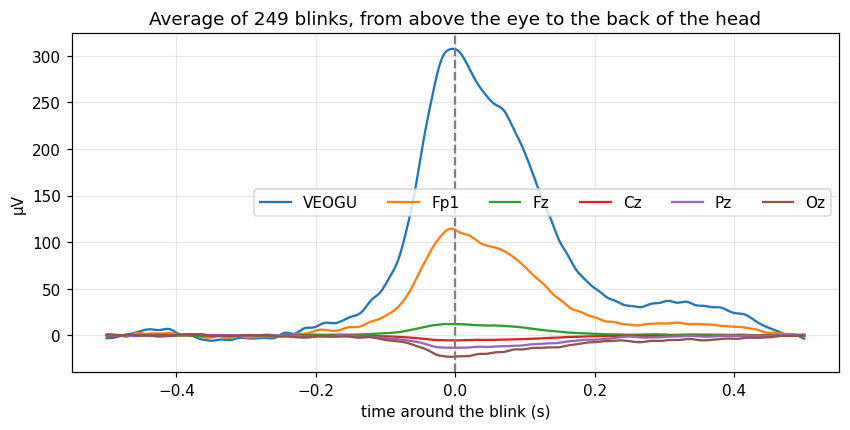

In [5]:
sf = raw.info["sfreq"]
key = validate.eye_answer_key(raw)                       # sample positions of real blinks (eye sensors)
blinks = np.c_[key, np.zeros_like(key), np.ones_like(key)]  # MNE's "events" format: (sample, 0, code)
print(f"answer key: {len(key)} blinks in {raw.times[-1]/60:.1f} minutes ({len(key)/(raw.times[-1]/60):.0f} per minute)")
blink_epochs = mne.Epochs(filtered, blinks, tmin=-0.5, tmax=0.5, baseline=(-0.5, -0.3), picks=["eeg", "eog"], preload=True)
avg = blink_epochs.average(picks=["eeg", "eog"])
fig, ax = plt.subplots(figsize=(9, 4))
for ch in ["VEOGU", "Fp1", "Fz", "Cz", "Pz", "Oz"]:
    ax.plot(avg.times, avg.get_data(picks=ch)[0]*1e6, label=ch)
ax.axvline(0, color="grey", ls="--"); ax.legend(ncol=6)
ax.set_xlabel("time around the blink (s)"); ax.set_ylabel("µV"); ax.set_title(f"Average of {len(blinks)} blinks, from above the eye to the back of the head")
plt.show()

### Detecting blinks WITHOUT eye sensors (what Sabi would have to do)

Sabi's cap has no eye sensors, so blinks must be found from the scalp alone. We use the fingerprint we just saw:

1. A **big swing on the forehead** (`Fp1`, `Fp2`): more than 4× their typical swing.
2. On **both** forehead sensors, **in the same direction** (a blink involves both eyes).
3. **Much smaller at the back of the head** (`Pz`, `POz`, `Oz`): less than 30% of the forehead size.
4. Only **one event per half second** (filtering turns each blink into an up- and a down-swing; that's one blink, not two).

Then we grade it against the answer key: how many real blinks did it find, and how many of its detections were real?
(A detection counts as a match if it's within 0.25 s of a real blink.)

In [6]:
X = quality.median_reference(raw.get_data(picks=scalp))
found = quality.detect_blinks(X, scalp, sf)
recall, precision = validate.match_events(found, key, sf)
print(f"scalp-only detector: {len(found)} blinks | found {recall:.0%} of the real blinks | {precision:.0%} of its detections were real")
reach = quality.blink_reach(X, scalp, sf, found)
print("how big this person's blinks are on each sensor, relative to the forehead:")
print({c: round(float(r), 2) for c, r in sorted(zip(scalp, reach), key=lambda t: -t[1]) if r > 0.15})

scalp-only detector: 259 blinks | found 96% of the real blinks | 92% of its detections were real


how big this person's blinks are on each sensor, relative to the forehead:
{'Fp2': 1.0, 'Fp1': 0.97, 'AFz': 0.41, 'F7': 0.29, 'F4': 0.21, 'F3': 0.19, 'F8': 0.18}


The detector should find most blinks while standing. The second line is the blink's reach: full size on `Fp1`/`Fp2`,
smaller on the next row back, then nothing. `quality.py` uses this reach to flag only the sensors a blink actually
affects (the **blink** check). Across all 10 people the results are in the report — including the honest finding that
while **jogging**, footstep swings get as big as blinks and blink detection breaks down, even with the eye sensors.

## 5. The motion sensors

The head motion sensor measures acceleration in 3 directions (in m/s²). When you stand still it still reads about
**9.8 in total — that's gravity**. When you jog, your head bounces up and down with every step.

Below: 5 seconds of head acceleration while **standing** vs **jogging**, then the head-bounce *spectrum* —
its peak tells us **steps per second**, exactly like the peak of a PPG spectrum tells you heart rate.

standing: IMU aligned to EEG; clock drift over session = +14.2 ms
jogging : IMU aligned to EEG; clock drift over session = +21.6 ms


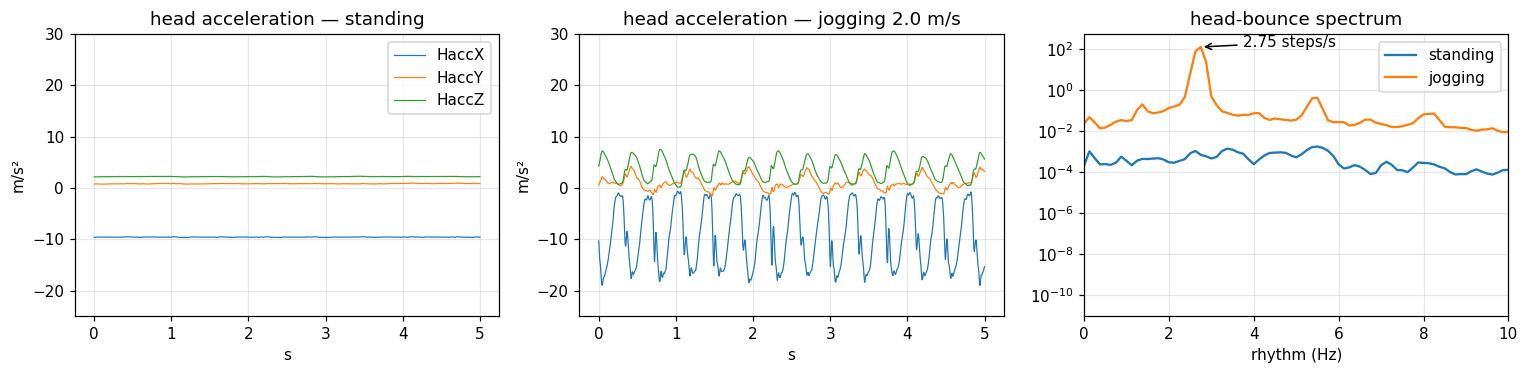

In [7]:
raw_jog = lee.load_eeg(SUB, JOGGING, TASK)
imu_stand = lee.load_imu_aligned(raw, SUB, STANDING, TASK)
imu_jog = lee.load_imu_aligned(raw_jog, SUB, JOGGING, TASK)
print("standing:", imu_stand.info["description"]); print("jogging :", imu_jog.info["description"])

acc = ["HaccX", "HaccY", "HaccZ"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, imu, label in [(axes[0], imu_stand, "standing"), (axes[1], imu_jog, "jogging 2.0 m/s")]:
    d = imu.get_data(picks=acc)
    i0 = int(100*sf); t = np.arange(int(5*sf))/sf
    for row, name in zip(d[:, i0:i0+len(t)], acc):
        ax.plot(t, row, label=name, lw=0.8)
    ax.set_title(f"head acceleration — {label}"); ax.set_xlabel("s"); ax.set_ylabel("m/s²"); ax.set_ylim(-25, 30)
axes[0].legend()
for imu, label in [(imu_stand, "standing"), (imu_jog, "jogging")]:
    x = imu.get_data(picks="HaccX")[0]
    f, p = welch(x - x.mean(), fs=sf, nperseg=int(8*sf))
    axes[2].semilogy(f, p, label=label)
    if label == "jogging":
        step = f[(f > 1) & (f < 4)][np.argmax(p[(f > 1) & (f < 4)])]
        axes[2].annotate(f"{step:.2f} steps/s", (step, p[f == step][0]), xytext=(step+1, p[f == step][0]), arrowprops=dict(arrowstyle="->"))
axes[2].set_xlim(0, 10); axes[2].set_xlabel("rhythm (Hz)"); axes[2].set_title("head-bounce spectrum"); axes[2].legend()
plt.tight_layout(); plt.show()

## 6. The key picture: what movement does to the brain signal

Same person, same sensors, **same vertical scale**. Left: standing. Right: jogging. Bottom: head acceleration.

**What to look for:** while jogging, many sensors get a slow, repeating wave that **lines up with the steps**
in the bottom plot. That is not brain activity — it's the sensors and cables wobbling on the head.
This is the core problem for a cap worn while moving (Sabi's situation), and what this project is about.

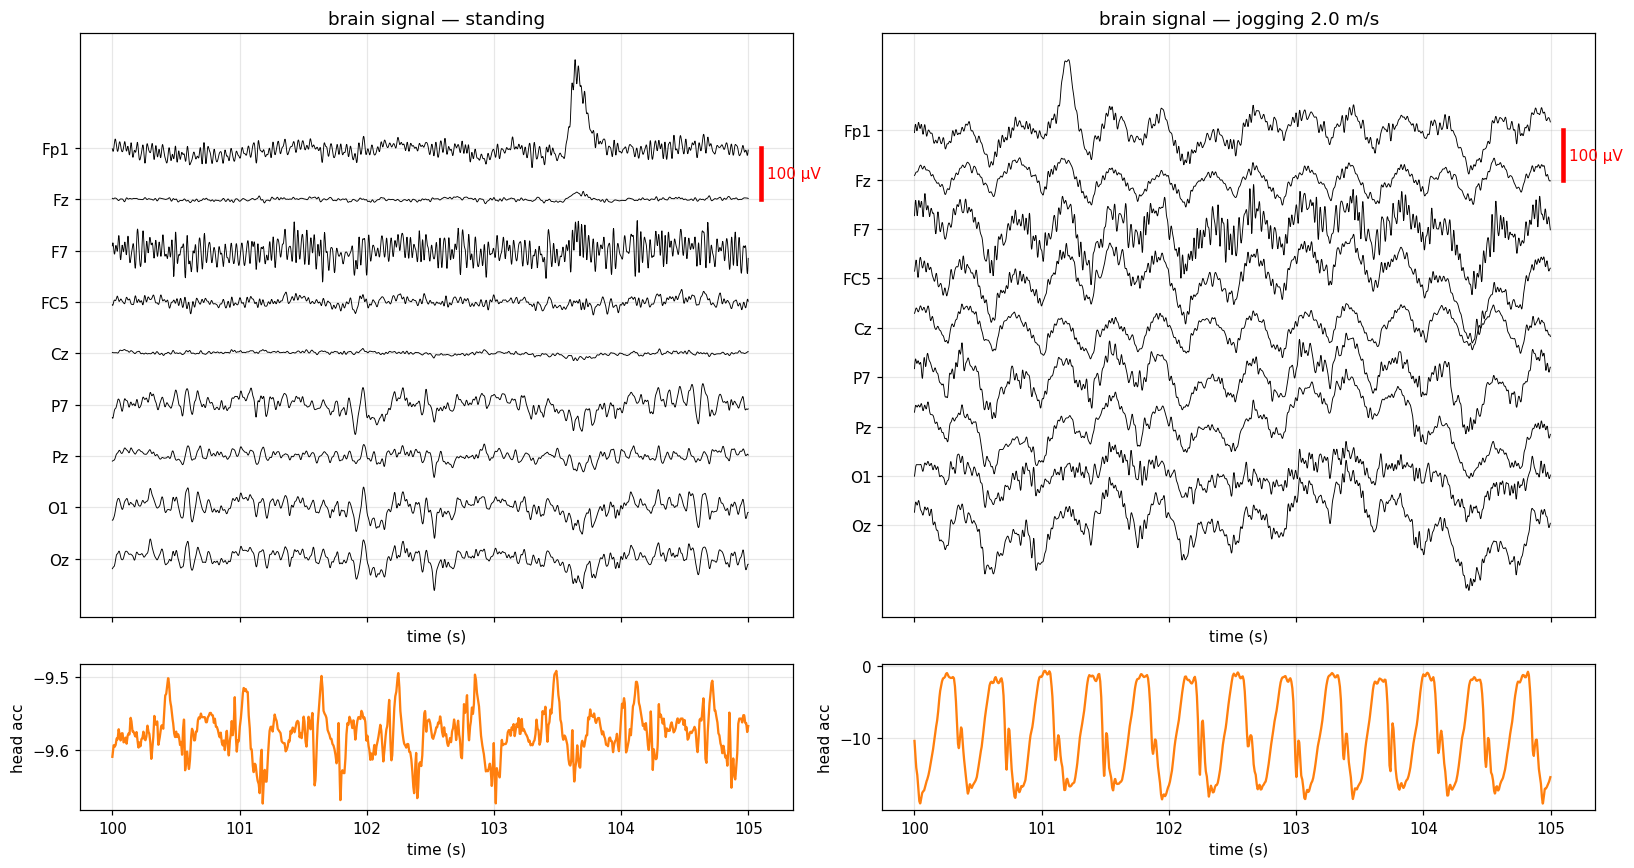

In [8]:
filt_jog = raw_jog.copy().filter(0.5, 40, picks=["eeg", "eog"])
show = ["Fp1", "Fz", "F7", "FC5", "Cz", "P7", "Pz", "O1", "Oz"]
fig, axes = plt.subplots(2, 2, figsize=(15, 8), gridspec_kw={"height_ratios": [4, 1]}, sharex="col")
for col, (r, imu, label) in enumerate([(filtered, imu_stand, "standing"), (filt_jog, imu_jog, "jogging 2.0 m/s")]):
    stacked_plot(r.get_data(picks=show)*1e6, show, sf, t0=100, dur=5, title=f"brain signal — {label}", ax=axes[0, col])
    i0 = int(100*sf); t = np.arange(i0, i0+int(5*sf))/sf
    axes[1, col].plot(t, imu.get_data(picks="HaccX")[0, i0:i0+len(t)], color="tab:orange")
    axes[1, col].set_ylabel("head acc"); axes[1, col].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

## 7. The frequency view (spectrum)

A spectrum answers: *how much of each rhythm is in this sensor?* Reading guide:

| Rhythm range | Name | What it usually is |
|---|---|---|
| 1–4 Hz | delta | deep sleep… or **slow artifacts: blinks, sweat, movement** |
| 4–8 Hz | theta | drowsiness, memory |
| **8–13 Hz** | **alpha** | relaxed / eyes closed — often a visible hump at the back of the head |
| 13–30 Hz | beta | active thinking, movement planning |
| > 30 Hz | gamma | real but tiny in EEG; mostly **muscle tension** dominates here |
| **exactly 60 Hz** | — | **electrical hum from the building's wiring** (Korea uses 60 Hz). A sharp spike here = sensor picking up hum |

The plot is on a log scale because power falls steeply with frequency (normal for brain signals).
**Red lines = sensors the dataset authors marked "bad".** Notice they split into two very different groups:

- **Two lines far *above* the rest from ~15 Hz upward** (`F7`, `Fp2`): extra "buzz" — typical of forehead/temple
  muscle tension or a poor contact.
- **Four lines far *below* the rest** (`Fz`, `FC1`, `FC2`, `Cz`): almost no signal at all. These four sit right around
  `FCz`, the **reference sensor** — every sensor's voltage is measured *relative to* FCz, and sensors next to it see
  nearly the same thing, so the difference is tiny. They're not necessarily broken; they're just badly placed
  for this reference. (Section 8 shows they look normal once we change the reference.)

Also notice the small spikes at **~45 Hz and ~75 Hz on every sensor** — probably electrical noise from equipment
in the room (treadmill motor, screen). Because they hit everyone equally, they say nothing about any one sensor.

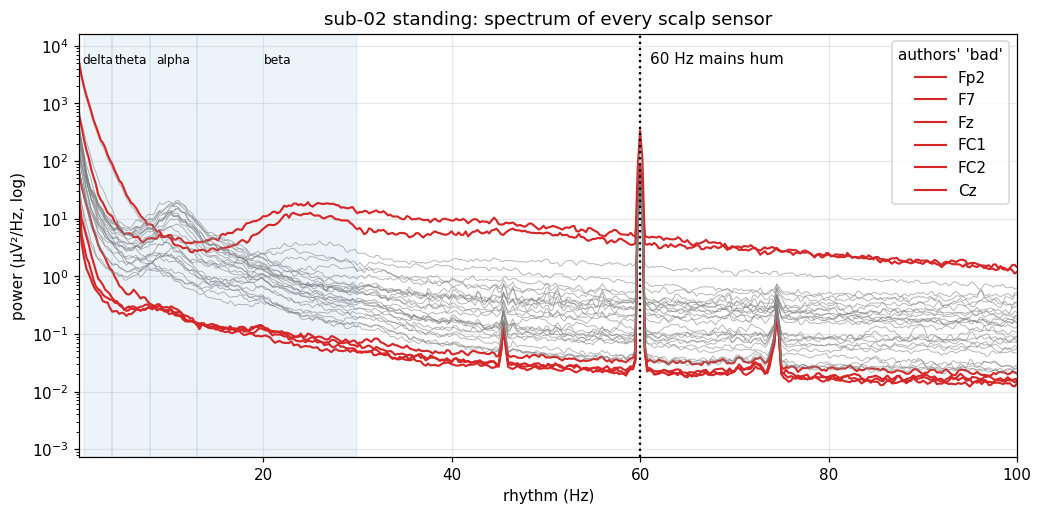

In [9]:
bad = lee.authors_bad_channels(SUB, STANDING, TASK)
X = raw.get_data(picks=scalp) * 1e6
f, P = welch(X, fs=sf, nperseg=int(4*sf))
fig, ax = plt.subplots(figsize=(11, 5))
for name, p in zip(scalp, P):
    ax.semilogy(f, p, color="tab:red" if name in bad else "grey", lw=1.4 if name in bad else 0.6, alpha=1 if name in bad else 0.6,
                label=name if name in bad else None)
for lo, hi, n in [(1,4,"delta"),(4,8,"theta"),(8,13,"alpha"),(13,30,"beta")]:
    ax.axvspan(lo, hi, alpha=0.08, color="C0"); ax.text((lo+hi)/2, ax.get_ylim()[1]*0.3, n, ha="center", fontsize=8)
ax.axvline(60, color="k", ls=":"); ax.text(61, ax.get_ylim()[1]*0.3, "60 Hz mains hum")
ax.set_xlim(0.5, 100); ax.set_xlabel("rhythm (Hz)"); ax.set_ylabel("power (µV²/Hz, log)"); ax.legend(title="authors' 'bad'")
ax.set_title(f"{SUB} standing: spectrum of every scalp sensor")
plt.show()

Now **standing vs jogging**, averaged over all scalp sensors. Jogging adds a lot of power at **low rhythms**, with
sharp peaks at the step rate (~2.75 Hz) and its multiples (5.5, 8.25… Hz), plus one at half the step rate (~1.4 Hz,
one full stride = left + right step) — the fingerprint of movement. Jogging also lifts everything above ~20 Hz a little
(neck and jaw muscles working harder). Note this overlaps the brain's
own delta/theta rhythms, which is why you can't simply filter movement away.

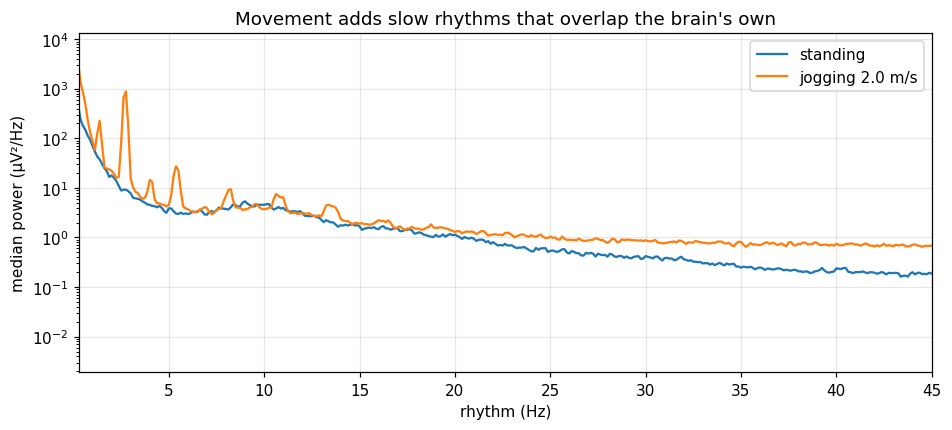

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for r, label in [(raw, "standing"), (raw_jog, "jogging 2.0 m/s")]:
    f, P = welch(r.get_data(picks=scalp)*1e6, fs=sf, nperseg=int(8*sf))
    ax.semilogy(f, np.median(P, axis=0), label=label)
ax.set_xlim(0.3, 45); ax.set_xlabel("rhythm (Hz)"); ax.set_ylabel("median power (µV²/Hz)"); ax.legend()
ax.set_title("Movement adds slow rhythms that overlap the brain's own"); plt.show()

## 8. The signal-quality checks ("tricks")

**Step 0 — fix the reference.** We just saw that measuring everything against one sensor (FCz) distorts the picture:
neighbours of FCz look dead, and FCz's own hum leaks into every sensor. So first we express every sensor relative to
the **median of all sensors** at each moment (a "median re-reference"). The median is used rather than the average
because a few bad sensors can't drag it around.

Then we cut each sensor's recording into **2-second windows** and ask simple questions about each window.
Every check targets one specific failure:

| Check | Plain question | What failure it catches | Why it works |
|---|---|---|---|
| **flat** | Is the signal frozen? | Dead / unplugged sensor | Real brain signal is never constant |
| **clipped** | Is it stuck at the maximum? | Signal too big for the recorder | Values pile up at the ceiling |
| **line_noise** | How much 60 Hz hum? | Loose or dry contact | A badly attached sensor acts as an antenna for the wiring in the walls |
| **high_freq_z** | Much buzzier (>30 Hz) than the other sensors? | Muscle tension (jaw, neck, forehead) | Muscles are much buzzier than brain. Compared against the other sensors, because the room adds a noise floor to everyone |
| **amplitude_z** | Much louder/quieter than the others? | Bad contact, bridged gel, movement | Brain signal is roughly the same size everywhere on the head |
| **pop_ratio** | Any sudden jump? (biggest step between readings ÷ typical step) | Contact briefly breaking ("pop") | Random noise gives ~5; real pops 16–900 (added in version 2) |
| **neighbour_corr** | Does it resemble *at least one* of its 4 nearest neighbours? | A sensor recording something local and non-brain | The skull blurs brain activity, so a healthy sensor always has a look-alike neighbour (same rule as the PREP pipeline: < 0.4 is suspicious) |

Each check becomes a **badness from 0 to 1** using two thresholds (warning, fail).
The **quality score = 1 − the worst badness**: one fatal problem is enough to make a window useless,
just like a PPG window with clipped signal is useless however good the rest looks.

*The thresholds are first guesses. Tuning and validating them is part of the project.*

In [11]:
def score_recording(r):
    pos = np.array([r.info["chs"][r.ch_names.index(c)]["loc"][:3] for c in scalp])
    feats = quality.window_features(r.get_data(picks=scalp), r.info["sfreq"], positions=pos, rereference=True)
    return feats, quality.quality_score(feats)

feats_s, score_s = score_recording(raw)
feats_j, score_j = score_recording(raw_jog)
table = quality.summary_table(scalp, feats_s, score_s, authors_bad=bad)
print(f"{SUB} STANDING — worst 10 sensors (median of each check over all 2-s windows)")
table.head(10).round(3)

sub-02 STANDING — worst 10 sensors (median of each check over all 2-s windows)


,flat,clipped,pop_ratio,line_noise,high_freq_z,amplitude_z,neighbour_corr,median_score,pct_windows_bad,pct_contact_bad,pct_artifact_bad,verdict,authors_label
AFz,0.004,0.0,4.768,0.276,-1.134,1.427,0.913,0.060,69.767,67.151,3.488,broken,
Fp1,0.003,0.0,5.963,0.214,0.976,3.156,0.910,0.097,96.512,59.593,57.849,broken,
Fp2,0.002,0.0,6.531,0.132,1.211,3.581,0.906,0.229,95.930,53.779,77.035,broken,bad
O1,0.006,0.0,7.289,0.035,0.089,0.036,0.905,1.000,12.209,10.174,2.035,ok,
PO8,0.004,0.0,7.300,0.038,0.629,0.734,0.920,1.000,12.500,9.884,3.198,ok,
PO4,0.007,0.0,7.302,0.024,-0.722,0.405,0.930,1.000,2.616,1.453,1.453,ok,
POz,0.007,0.0,6.176,0.011,-0.822,-0.425,0.805,1.000,0.872,0.291,0.581,ok,
PO3,0.007,0.0,5.941,0.006,-1.076,-0.134,0.853,1.000,0.581,0.000,0.581,ok,
PO7,0.006,0.0,8.466,0.018,0.063,0.680,0.871,1.000,3.198,1.163,2.035,ok,
P8,0.006,0.0,6.115,0.028,-0.106,0.646,0.911,1.000,2.616,2.326,0.291,ok,


**How to read this table:** each row is a sensor, sorted from worst to best. `pct_windows_bad` is the share of
2-second windows that scored below 0.5. Compare the right-most column (the authors' labels) with our score.

- We **agree** on `Fp2` — extra mains hum and a larger signal than the others.
- We **miss** `F7`. It *is* buzzier than the others (you can see it in the spectrum), but not by enough to cross our
  first-guess threshold. That's a tuning question — exactly what checking against labels is for.
- We **don't** flag `Fz`, `FC1`, `FC2`, `Cz`: after the re-reference they behave normally, so the authors most likely
  marked them because they looked dead *relative to FCz*. A real example of why labels aren't ground truth.
- We flag `AFz` and `Fp1`, which the authors didn't. `AFz` sits right next to the **ground** sensor (`Fpz`), and the
  forehead sensors carry the most mains hum in this recording.

Disagreements are interesting, not failures: the authors made one human judgement per recording, ours is measured
every 2 seconds.

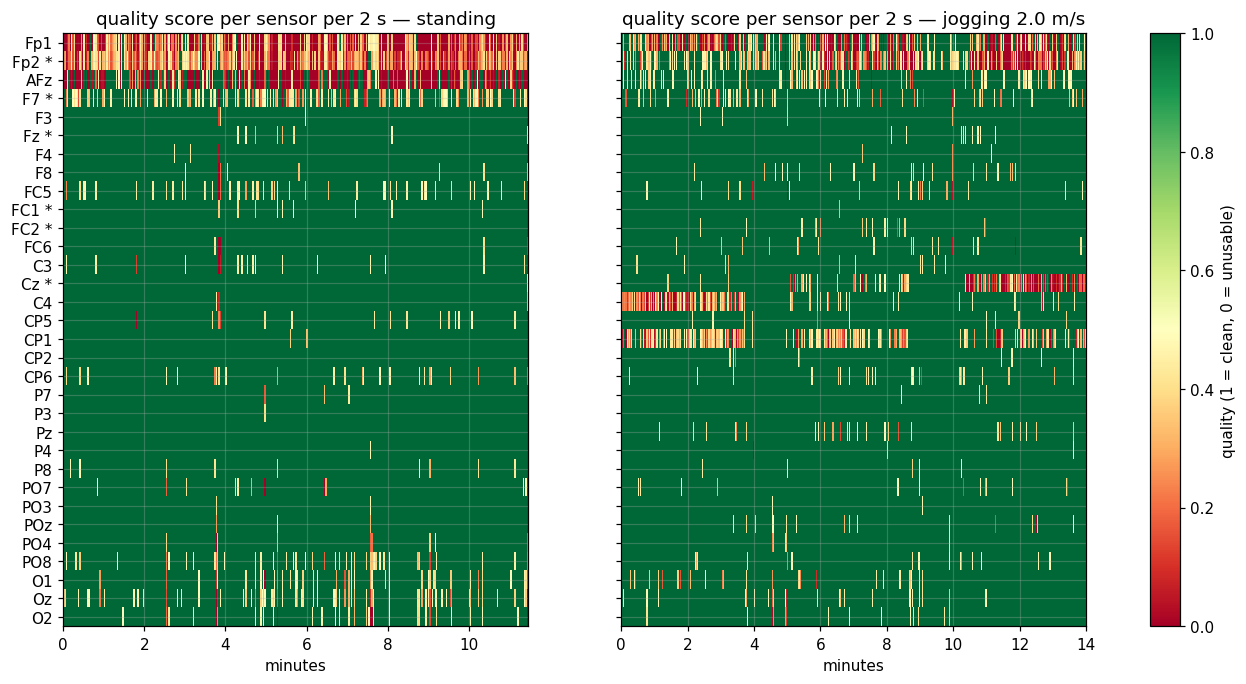

* = marked bad by the dataset authors


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
for ax, sc, label in [(axes[0], score_s, "standing"), (axes[1], score_j, "jogging 2.0 m/s")]:
    im = ax.imshow(sc, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest",
                   extent=[0, sc.shape[1]*2/60, len(scalp)-0.5, -0.5])
    ax.set_title(f"quality score per sensor per 2 s — {label}"); ax.set_xlabel("minutes")
axes[0].set_yticks(range(len(scalp)), [f"{c} *" if c in bad else c for c in scalp])
fig.colorbar(im, ax=axes, label="quality (1 = clean, 0 = unusable)")
plt.show()
print("* = marked bad by the dataset authors")

**What to look for:**
- **Red all the time, standing *and* jogging** (`Fp1`, `Fp2`, `AFz`): a problem from the start — these forehead sensors
  carry the most mains hum. A contact/placement issue, not movement.
- **Red only in a stretch of the jogging recording** (`C4` and `CP1` for the first ~4 minutes, `Cz` after ~10 minutes):
  sensors that went bad *during* movement — most likely loosened and wobbling. Section 9 confirms this independently:
  the same sensors are the hot spots in the "moves with the head" map.

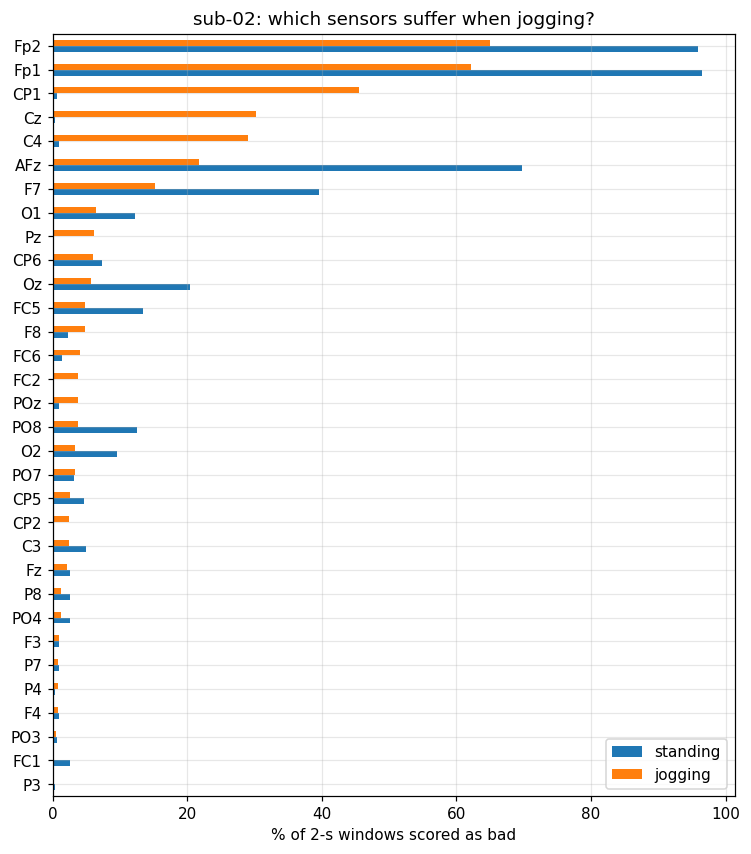

standing: what made windows bad (% of bad windows) -> {'line_noise': 60.5, 'amplitude_z': 30.2, 'pop_ratio': 6.3, 'high_freq_z': 1.6, 'neighbour_corr': 1.3}
jogging: what made windows bad (% of bad windows) -> {'line_noise': 36.6, 'neighbour_corr': 35.3, 'amplitude_z': 21.0, 'pop_ratio': 6.4, 'high_freq_z': 0.7}


In [13]:
pct = pd.DataFrame({"standing": 100*(score_s < 0.5).mean(1), "jogging": 100*(score_j < 0.5).mean(1)}, index=scalp)
ax = pct.sort_values("jogging").plot.barh(figsize=(8, 9))
ax.set_xlabel("% of 2-s windows scored as bad"); ax.set_title(f"{SUB}: which sensors suffer when jogging?")
plt.show()

# Which check is responsible? Share of bad windows where each check was the worst one.
for label, feats, sc in [("standing", feats_s, score_s), ("jogging", feats_j, score_j)]:
    b = quality.badness(feats); names = list(b); worst = np.argmax(np.stack([b[n] for n in names]), axis=0)
    culprit = pd.Series([names[i] for i in worst[sc < 0.5]]).value_counts(normalize=True).mul(100).round(1)
    print(f"{label}: what made windows bad (% of bad windows) ->", culprit.to_dict())

## 9. A movement-specific check: does the sensor move *with the head*?

The checks above don't use the motion sensor at all. This one does, and it's the most relevant to a cap worn
while moving. For every scalp sensor we measure **coherence** with the head's vertical acceleration:
a number from 0 to 1 that says how consistently the two signals rise and fall *together* at the same rhythms
(regardless of their size). Brain activity has no reason to follow your footsteps; a wobbling sensor does.

The head maps show where on the scalp the signal is most tied to head movement.

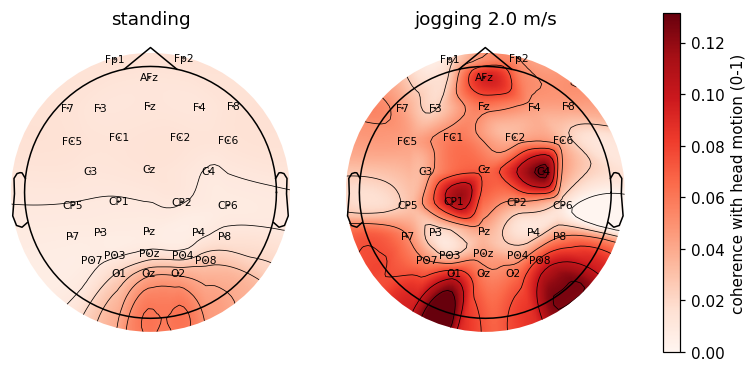

     standing  jogging 2.0 m/s
C4       0.01             0.13
CP1      0.01             0.11
AFz      0.01             0.09
O1       0.02             0.08
PO8      0.03             0.08
Cz       0.01             0.07
FC1      0.01             0.06
O2       0.04             0.06


In [14]:
pos_info = raw.copy().pick(scalp).info
mc = {}
for r, imu, label in [(raw, imu_stand, "standing"), (raw_jog, imu_jog, "jogging 2.0 m/s")]:
    mc[label] = quality.motion_coupling(quality.median_reference(r.get_data(picks=scalp)), imu.get_data(picks="HaccX")[0], sf)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (label, v) in zip(axes, mc.items()):
    im, _ = mne.viz.plot_topomap(v, pos_info, axes=ax, show=False, vlim=(0, max(map(max, mc.values()))), names=scalp, cmap="Reds")
    ax.set_title(label)
fig.colorbar(im, ax=axes, label="coherence with head motion (0-1)")
plt.show()
print(pd.DataFrame(mc, index=scalp).sort_values("jogging 2.0 m/s", ascending=False).head(8).round(2))

## 10. Does the score get worse as people move faster? (an honest surprise)

Below we score all four speeds for this person. We look at two numbers: the share of windows our checks call
bad (all checks except the motion one), and how strongly the sensors move with the head (motion coupling, averaged over all sensors).

In [15]:
rows = []
for ses in ["ses-02", "ses-03", "ses-04", "ses-05"]:
    r = lee.load_eeg(SUB, ses, TASK); imu = lee.load_imu_aligned(r, SUB, ses, TASK)
    feats, sc = score_recording(r)
    mcs = quality.motion_coupling(quality.median_reference(r.get_data(picks=scalp)), imu.get_data(picks="HaccX")[0], sf)
    rows.append({"speed": lee.SPEEDS[ses], "% windows bad (no motion check)": 100*(sc < 0.5).mean(),
                 "mean motion coupling": mcs.mean(), "head bounce (sd of acc, m/s²)": imu.get_data(picks="HaccX")[0].std()})
speed_table = pd.DataFrame(rows).set_index("speed").round(3)
speed_table

,% windows bad (no motion check),mean motion coupling,"head bounce (sd of acc, m/s²)"
speed,,,
standing (0 m/s),12.827,0.014,0.076
slow walk (0.8 m/s),16.009,0.017,1.076
fast walk (1.6 m/s),10.380,0.042,2.989
light jog (2.0 m/s),10.640,0.050,5.665


**What this shows:** head movement and motion coupling rise steadily with speed, but the share of "bad" windows from
these checks **does not**. That's not a bug — it's the most important lesson of this notebook:

> These checks compare each sensor **against the other sensors**. When the whole cap shakes, every sensor gets
> worse together, so nobody stands out. They're great at finding *one bad sensor*, and blind to *everyone being bad
> at once*.

That's exactly why a cap worn while moving needs a **motion-aware** check that uses the motion sensor directly.
Version 2 of `quality.py` adds one: with it, the bad share rises from 13% standing to 34% jogging for this person
(see the report).

## 11. What you should now be able to explain (out loud, without notes)

1. What an EEG sensor measures, why the signal is so small (µV), and why neighbouring sensors look alike.
2. What `Fp1`, `Cz`, `Pz`, `O2` mean and roughly where they are.
3. How a blink looks, and how you'd recognise it from the scalp alone (big, slow, both forehead sensors, fading backwards).
4. Why the 60 Hz spike in a sensor's spectrum suggests a poor contact.
5. What movement does to EEG: step-locked slow waves that overlap the brain's own slow rhythms.
6. Why we re-reference first, and why the sensors next to the reference looked "bad".
7. The quality checks, what failure each catches, and why the score uses the **worst** check.
8. Why these checks can't see movement that affects the whole cap — and what we need instead.
9. Why the authors' "bad" labels are useful but not ground truth.

### Honest limitations of this first version (= what the project improves next)
- Thresholds are guesses → tune them on several people and check against the authors' labels.
- "Clean" isn't proven yet → next we check whether high-scoring sensors actually show the brain's
  "spotted it!" bump more clearly (that's the real test of a quality score).
- Motion coupling is measured here but not part of this score → added in version 2 (see the report).